Text(0, 0.5, 'Position')

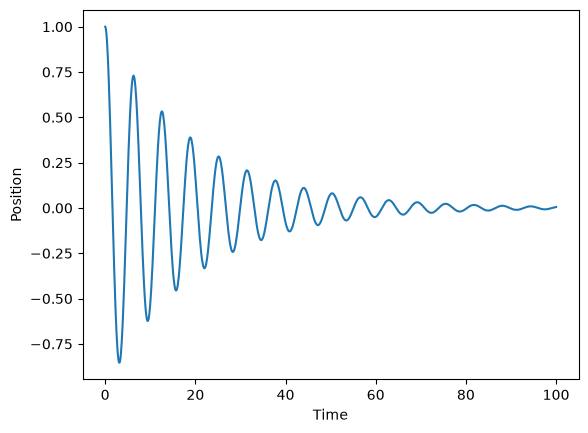

In [1]:
import numpy as np
import matplotlib.pyplot as plt

k = 1                 # spring constant
m = 1                 # mass
gamma = 0.1           # damping coefficient
t_end = 100           # final time
dt = 0.1               # time step
y0 = np.array([1, 0])  # initial conditions: position, velocity

t = np.arange(0, t_end + dt, dt)  # time vector, including t_end
n = len(t) 

y = np.zeros((2, n))              # solution matrix: row 0 = position, row 1 = velocity
y[:, 0] = y0                      # set initial conditions

for i in range(n - 1):
    k1 = np.array([
        y[1, i],
        -(gamma / m * y[1, i] + k / m * y[0, i])
    ])

    k2 = np.array([
        y[1, i] + 0.5 * dt * k1[1],
        -k / m * (y[0, i] + 0.5 * dt * k1[0])
        - gamma / m * (y[1, i] + 0.5 * dt * k1[1])
    ])

    k3 = np.array([
        y[1, i] + 0.5 * dt * k2[1],
        -k / m * (y[0, i] + 0.5 * dt * k2[0])
        - gamma / m * (y[1, i] + 0.5 * dt * k2[1])
    ])

    k4 = np.array([
        y[1, i] + dt * k3[1],
        -k / m * (y[0, i] + dt * k3[0])
        - gamma / m * (y[1, i] + dt * k3[1])
    ])

    # update solution
    y[:, i + 1] = y[:, i] + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6

plt.plot(t, y[0, :])
plt.xlabel("Time")
plt.ylabel("Position")